# Black Friday Purchase Analysis

Exploratory data analysis and hypothesis testing on retail purchase data (User demographics, product categories, and purchase amount).

**Dataset:** Black Friday / Walmart purchase dataset ([source on Kaggle](https://www.kaggle.com/datasets/sdolezel/black-friday)) -- place `purchase_case_study_inferential_statistics.csv` in the same folder as this notebook (or update the path below) to run it.

**What this notebook covers:**
- Data cleaning (missing values, inconsistent category labels)
- Outlier detection and removal (IQR method)
- Categorical encoding
- Two hypothesis tests (one-sample and two-sample t-tests) on purchase behavior

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Data

In [2]:
df=pd.read_csv("/content/purchase_case_study_inferential_statistics.csv")

In [3]:
df

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10.0,A,2,0.0,3.0,NaN,NaN,8370.0
1,1000001,P00248942,F,0-17,10.0,A,2,0.0,1.0,6.0,14.0,15200.0
2,1000001,P00087842,F,0-17,10.0,A,2,0.0,12.0,NaN,NaN,1422.0
3,1000001,P00085442,F,0-17,10.0,A,2,0.0,12.0,14.0,NaN,1057.0
4,1000002,P00285442,M,55+,16.0,C,4+,0.0,8.0,NaN,NaN,7969.0
...,...,...,...,...,...,...,...,...,...,...,...,...
263010,1004473,P00041942,M,36-45,1.0,B,3,0.0,5.0,18.0,NaN,3722.0
263011,1004473,P00115142,M,36-45,1.0,B,3,0.0,1.0,8.0,17.0,19253.0
263012,1004473,P00188442,M,36-45,1.0,B,3,0.0,5.0,7.0,NaN,3608.0
263013,1004473,P00119442,M,36-45,1.0,B,3,0.0,5.0,NaN,NaN,3604.0


In [4]:
df.shape

(263015, 12)

## Initial Exploration

Working on a copy of the raw data (`df1`) so the original (`df`) stays untouched for reference.

In [5]:
df1=df.copy()

In [6]:
df1.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10.0,A,2,0.0,3.0,NaN,NaN,8370.0
1,1000001,P00248942,F,0-17,10.0,A,2,0.0,1.0,6.0,14.0,15200.0
2,1000001,P00087842,F,0-17,10.0,A,2,0.0,12.0,NaN,NaN,1422.0
3,1000001,P00085442,F,0-17,10.0,A,2,0.0,12.0,14.0,NaN,1057.0
4,1000002,P00285442,M,55+,16.0,C,4+,0.0,8.0,NaN,NaN,7969.0


In [7]:
df1.tail()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
263010,1004473,P00041942,M,36-45,1.0,B,3,0.0,5.0,18.0,NaN,3722.0
263011,1004473,P00115142,M,36-45,1.0,B,3,0.0,1.0,8.0,17.0,19253.0
263012,1004473,P00188442,M,36-45,1.0,B,3,0.0,5.0,7.0,NaN,3608.0
263013,1004473,P00119442,M,36-45,1.0,B,3,0.0,5.0,NaN,NaN,3604.0
263014,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df1.shape

(263015, 12)

In [9]:
df1.columns

Index(['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category',
       'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1',
       'Product_Category_2', 'Product_Category_3', 'Purchase'],
      dtype='object')

In [10]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 263015 entries, 0 to 263014
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     263015 non-null  int64  
 1   Product_ID                  263014 non-null  object 
 2   Gender                      263014 non-null  object 
 3   Age                         263014 non-null  object 
 4   Occupation                  263014 non-null  float64
 5   City_Category               263014 non-null  object 
 6   Stay_In_Current_City_Years  263014 non-null  object 
 7   Marital_Status              263014 non-null  float64
 8   Product_Category_1          263014 non-null  float64
 9   Product_Category_2          181501 non-null  float64
 10  Product_Category_3          80582 non-null   float64
 11  Purchase                    263014 non-null  float64
dtypes: float64(6), int64(1), object(5)
memory usage: 24.1+ MB


## Data Cleaning

**Issue found:** `Stay_In_Current_City_Years` mixes numeric strings with the non-numeric label `'4+'`, which blocks it from being used as a number. Standardizing it to `4` makes the column usable for analysis.

In [11]:
df['Stay_In_Current_City_Years'].unique()

array(['2', '4+', '3', '1', '0', nan], dtype=object)

In [12]:
df1['Stay_In_Current_City_Years']=df1['Stay_In_Current_City_Years'].replace('4+','4')

In [13]:
df1['Stay_In_Current_City_Years'].unique()

array(['2', '4', '3', '1', '0', nan], dtype=object)

In [14]:
df1['Stay_In_Current_City_Years']=df1['Stay_In_Current_City_Years'].fillna('0')

In [15]:
df1['Stay_In_Current_City_Years'].unique()

array(['2', '4', '3', '1', '0'], dtype=object)

In [16]:
df1['Stay_In_Current_City_Years']=df1['Stay_In_Current_City_Years'].astype(int)

In [17]:
df1['Stay_In_Current_City_Years'].unique()

array([2, 4, 3, 1, 0])

In [18]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 263015 entries, 0 to 263014
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     263015 non-null  int64  
 1   Product_ID                  263014 non-null  object 
 2   Gender                      263014 non-null  object 
 3   Age                         263014 non-null  object 
 4   Occupation                  263014 non-null  float64
 5   City_Category               263014 non-null  object 
 6   Stay_In_Current_City_Years  263015 non-null  int64  
 7   Marital_Status              263014 non-null  float64
 8   Product_Category_1          263014 non-null  float64
 9   Product_Category_2          181501 non-null  float64
 10  Product_Category_3          80582 non-null   float64
 11  Purchase                    263014 non-null  float64
dtypes: float64(6), int64(2), object(4)
memory usage: 24.1+ MB


**Missing values:** `Product_Category_2` and `Product_Category_3` are missing whenever a product doesn't belong to a second or third category -- this is expected, so missing values are filled with `0` (meaning "not applicable") rather than dropped. Remaining rows with missing core fields are dropped.

In [19]:
df1.isnull().sum()

,0
User_ID,0
Product_ID,1
Gender,1
Age,1
Occupation,1
City_Category,1
Stay_In_Current_City_Years,0
Marital_Status,1
Product_Category_1,1
Product_Category_2,81514


In [20]:
df1[['Product_Category_2','Product_Category_3']]=df1[['Product_Category_2','Product_Category_3']].fillna(0)

In [21]:
df1.isnull().sum()

,0
User_ID,0
Product_ID,1
Gender,1
Age,1
Occupation,1
City_Category,1
Stay_In_Current_City_Years,0
Marital_Status,1
Product_Category_1,1
Product_Category_2,0


In [22]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 263015 entries, 0 to 263014
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     263015 non-null  int64  
 1   Product_ID                  263014 non-null  object 
 2   Gender                      263014 non-null  object 
 3   Age                         263014 non-null  object 
 4   Occupation                  263014 non-null  float64
 5   City_Category               263014 non-null  object 
 6   Stay_In_Current_City_Years  263015 non-null  int64  
 7   Marital_Status              263014 non-null  float64
 8   Product_Category_1          263014 non-null  float64
 9   Product_Category_2          263015 non-null  int64  
 10  Product_Category_3          263015 non-null  int64  
 11  Purchase                    263014 non-null  float64
dtypes: float64(4), int64(4), object(4)
memory usage: 24.1+ MB


In [23]:
df1.isnull().sum()

,0
User_ID,0
Product_ID,1
Gender,1
Age,1
Occupation,1
City_Category,1
Stay_In_Current_City_Years,0
Marital_Status,1
Product_Category_1,1
Product_Category_2,0


In [24]:
df1.dropna(inplace = True)

In [25]:
df1.isnull().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,0


In [26]:
df1.duplicated().sum()

np.int64(0)

## Outlier Detection and Removal

Checking the `Purchase` column for outliers using a boxplot, then removing values outside the IQR-based bounds so they don't skew later statistical tests.

<function matplotlib.pyplot.show(close=None, block=None)>

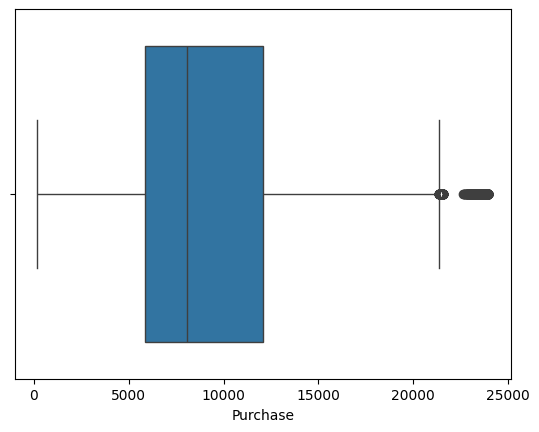

In [27]:
sns.boxplot(x=df1['Purchase'])
plt.show

In [28]:
Q1=df1['Purchase'].quantile(0.25)
Q3=df1['Purchase'].quantile(0.75)
IQR=Q3-Q1
LB = Q1-1.5*IQR
UB = Q3+1.5*IQR
print('Q1',Q1)
print('Q3',Q3)
print('IQR',IQR)
print('LB',LB)
print('UB',UB)

Q1 5863.0
Q3 12059.0
IQR 6196.0
LB -3431.0
UB 21353.0


In [ ]:
df1 = df1[
      (df1['Purchase']>=LB)&
      (df1['Purchase']<=UB)
].copy()

<function matplotlib.pyplot.show(close=None, block=None)>

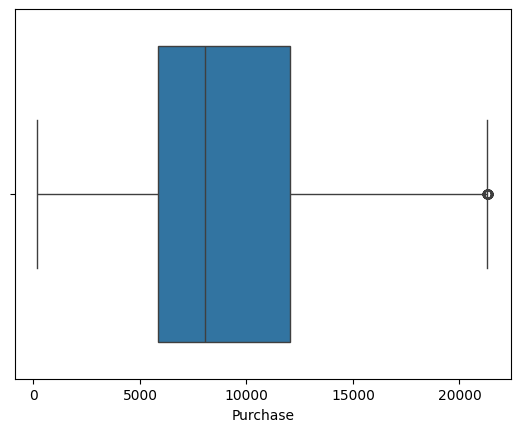

In [29]:
sns.boxplot(x=df1['Purchase'])
plt.show

In [30]:
df1.shape

(261725, 12)

## Encoding Categorical Variables

`Gender`, `Age`, `City_Category`, and `Product_ID` are converted to numeric labels so they can be used in statistical comparisons below.

In [31]:
#label encoding
cols=['Gender','Age','City_Category', 'Product_ID']
df1['Age'].unique()


array(['0-17', '55+', '26-35', '46-50', '51-55', '36-45', '18-25'],
      dtype=object)

In [32]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for col in cols:
  df1[col]=le.fit_transform(df1[col])

/tmp/ipykernel_6832/3429634667.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1[col]=le.fit_transform(df1[col])
/tmp/ipykernel_6832/3429634667.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1[col]=le.fit_transform(df1[col])
/tmp/ipykernel_6832/3429634667.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_

In [33]:
df1[['Gender','Age','City_Category', 'Product_ID']].head(20)

,Gender,Age,City_Category,Product_ID
0,0,0,0,647
1,0,0,0,2304
2,0,0,0,814
3,0,0,0,790
4,1,6,2,2657
5,1,2,0,1768
6,1,4,1,1684
7,1,4,1,3213
8,1,4,1,3481
9,1,2,0,2554


In [34]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 261725 entries, 0 to 263013
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     261725 non-null  int64  
 1   Product_ID                  261725 non-null  int64  
 2   Gender                      261725 non-null  int64  
 3   Age                         261725 non-null  int64  
 4   Occupation                  261725 non-null  float64
 5   City_Category               261725 non-null  int64  
 6   Stay_In_Current_City_Years  261725 non-null  int64  
 7   Marital_Status              261725 non-null  float64
 8   Product_Category_1          261725 non-null  float64
 9   Product_Category_2          261725 non-null  int64  
 10  Product_Category_3          261725 non-null  int64  
 11  Purchase                    261725 non-null  float64
dtypes: float64(4), int64(8)
memory usage: 26.0 MB


## Hypothesis Test 1: Is the average purchase by men aged 18-25 ₹10,000?

**Setup:** a one-sample t-test compares the mean `Purchase` value of a random sample of men aged 18-25 against a fixed assumed value (₹10,000).

- **H0 (null):** the average purchase amount equals ₹10,000
- **H1 (alternative):** the average purchase amount is not ₹10,000
- **Significance level:** α = 0.05

In [35]:
new_data = df1[(df1["Age"]==1)&(df1["Gender"]==1)]
new_data


,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
97,1000021,2024,1,1,16.0,1,0,0.0,3.0,12,0,3055.0
98,1000022,3261,1,1,15.0,0,4,0.0,1.0,8,17,12099.0
99,1000022,1954,1,1,15.0,0,4,0.0,5.0,8,0,8797.0
100,1000022,1792,1,1,15.0,0,4,0.0,3.0,4,0,10681.0
101,1000022,1020,1,1,15.0,0,4,0.0,8.0,14,0,7801.0
...,...,...,...,...,...,...,...,...,...,...,...,...
262767,1004446,1311,1,1,18.0,1,1,1.0,1.0,2,0,15431.0
262951,1004465,2880,1,1,4.0,0,1,1.0,5.0,0,0,1763.0
262952,1004465,1296,1,1,4.0,0,1,1.0,2.0,3,4,3240.0
262953,1004465,2733,1,1,4.0,0,1,1.0,8.0,0,0,5832.0


In [36]:
new_data.shape

(36202, 12)

In [37]:
sample=new_data.sample(3600,random_state=5)

In [38]:
sample["Purchase"].mean()

np.float64(9492.950833333334)

In [39]:
from scipy.stats import ttest_1samp


In [40]:
a_mean = 10000
t_value,p_value=ttest_1samp(sample["Purchase"],a_mean)
p_value

np.float64(1.7766468838738448e-09)

In [41]:
if p_value<0.05:
  print("Reject the null hypothesis")
else:
  print("Accept the null hypothesis")

Reject the null hypothesis


**Result:** p-value ≈ 1.78e-09, which is far below 0.05, so we reject H0. The average purchase amount for this group is NOT ₹10,000 -- it's significantly different (actual sample mean ≈ ₹9,493).

## Hypothesis Test 2: Do men and women aged 18-25 spend the same on average?

**Setup:** an independent two-sample t-test compares mean `Purchase` between men and women in the 18-25 age group.

- **H0 (null):** average purchase amount is the same for men and women
- **H1 (alternative):** average purchase amount differs between men and women
- **Significance level:** α = 0.05

In [42]:
men=df1[(df1["Age"]==1)&(df1["Gender"]==1)]["Purchase"]
women=df1[(df1["Age"]==1)&(df1["Gender"]==0)]["Purchase"]




In [43]:
print(len(men))
print(len(women))

36202
11840


In [44]:
print(men.mean())
print(women.mean())


9391.676371471189
8379.589527027027


In [45]:
from scipy.stats import ttest_ind

In [46]:
t_value,p_value=ttest_ind(men,women)
p_value

np.float64(1.4910824433801244e-84)

In [47]:
if p_value<0.05:
  print("Reject the null hypothesis")
else:
  print("Accept the null hypothesis")

Reject the null hypothesis


**Result:** p-value ≈ 1.49e-84, far below 0.05, so we reject H0. Men and women aged 18-25 do NOT spend the same on average -- in this sample, men spent more (≈ ₹9,392) than women (≈ ₹8,380).

## Conclusion

- The dataset required cleaning: standardizing `Stay_In_Current_City_Years`, filling expected missing values in product category columns, and removing outliers in `Purchase` using the IQR method.
- **Finding 1:** Men aged 18-25 do not spend an average of ₹10,000 per transaction -- their actual average (≈ ₹9,493 in this sample) is statistically significantly different from that benchmark.
- **Finding 2:** Purchase amount differs significantly by gender within the 18-25 age group, with men spending more on average (≈ ₹9,392) than women (≈ ₹8,380).
- **Business takeaway:** if ₹10,000 was being used as a planning assumption for average basket size in this age group, it should be revised downward, and any marketing or inventory strategy segmented by gender within this age group should account for the spending gap observed here.